## 1. Cel pracy i model fizyczny

W projekcie sprawdzamy, jak pole elektryczne $\mathcal{E}$ oraz czas życia nośników $\tau_p$ wpływają na ruch, rozpływanie się i zanik chmury nadmiarowych dziur $\Delta p(x, t)$ w krzemie typu *n* (eksperyment Haynesa–Shockleya). Zjawisko opisuje równanie ciągłości w 1D (Sze & Ng, 2006, wzory 167–168):

$$\frac{\partial (\Delta p)}{\partial t} + \mu_p \mathcal{E} \frac{\partial (\Delta p)}{\partial x} = D_p \frac{\partial^2 (\Delta p)}{\partial x^2} - \frac{\Delta p}{\tau_p}$$

Symulację zaczynamy w chwili $t_0 = 1\ \mu\text{s}$ od gładkiego impulsu Gaussa (zamiast nieskończenie wąskiej szpilki w $t = 0$, której nie da się zapisać na siatce):

$$\Delta p(x, t_0) = \frac{N'}{\sqrt{4\pi D_p t_0}} \exp\left(-\frac{x^2}{4 D_p t_0} - \frac{t_0}{\tau_p}\right)$$

**Dlaczego takie wartości parametrów?** Wybrano typowe dane dla krzemu typu *n* w temperaturze pokojowej ($300\ \text{K}$): ruchliwość dziur $\mu_p = 480\ \text{cm}^2/(\text{V}\cdot\text{s})$, współczynnik dyfuzji $D_p = 12\ \text{cm}^2/\text{s}$ (zależne od siebie przez relację Einsteina $D_p / \mu_p \approx 0{,}025\ \text{V}$), czas życia $\tau_p = 10\ \mu\text{s}$ oraz dawkę $N' = 10^{12}\ \text{cm}^{-2}$. Pole $\mathcal{E} = 25\ \text{V/cm}$ sprawia, że paczka przesuwa się o $720\ \mu\text{m}$ w czasie symulacji ($t \in [1, 7]\ \mu\text{s}$), więc dobrze widać jej ruch i zanik, a jednocześnie nie dociera do brzegu obszaru ($0{,}2\ \text{cm}$).

## 2. Metoda obliczeń

Ruch (dryf) i rozpływanie się paczki (dyfuzję) liczy biblioteka `PyMPDATA` (3 iteracje, `nonoscillatory=True`, `non_zero_mu_coeff=True`), która pilnuje, aby stężenie nigdzie nie spadło poniżej zera. Zanik nośników (rekombinację $-\Delta p / \tau_p$) doliczamy osobno w każdym kroku metodą rozszczepienia Stranga: najpierw odejmujemy pół kroku rekombinacji, potem wykonujemy krok transportu w `PyMPDATA`, a na końcu drugie pół kroku rekombinacji.

Do samej rekombinacji użyto prostego **schematu Eulera** ($\Delta p \leftarrow \Delta p - \frac{\Delta t}{2\tau_p}\Delta p$). Wystarcza on w zupełności, bo krok czasowy $\Delta t$ jest bardzo mały w porównaniu z czasem życia $\tau_p$ — w jednym kroku znika tylko ułamek procenta nośników, więc metoda jest stabilna i dokładna, a kod pozostaje prosty.

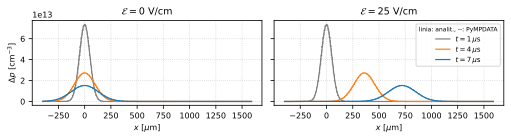

In [3]:
%config InlineBackend.figure_format = 'svg'
import os
os.environ['NUMBA_THREADING_LAYER'] = 'workqueue'
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from PyMPDATA import (Options, ScalarField, Solver, Stepper,
                      VectorField, boundary_conditions)

plt.rcParams.update({'font.size': 8})
N, D, mu_p, tau, t0, t1, E = 1e12, 12.0, 480.0, 10e-6, 1e-6, 7e-6, 25.0
opts = Options(n_iters=3, non_zero_mu_coeff=True, nonoscillatory=True)

def analytical(x, t):
    return N / np.sqrt(4 * np.pi * D * t) * np.exp(-x**2 / (4 * D * t) - t / tau)

def solve(nx, nt, outfreq, field=E):
    x, dx = np.linspace(-0.04, 0.16, nx, endpoint=False, retstep=True)
    dt = (t1 - t0) / nt
    C, mu_num = mu_p * field * dt / dx, D * dt / dx**2
    assert abs(C) + 2 * mu_num < 1.0
    bcs = (boundary_conditions.Periodic(),)
    psi0 = analytical(x, t0)
    sol = Solver(Stepper(options=opts, n_dims=1),
                 ScalarField(psi0.copy(), opts.n_halo, bcs),
                 VectorField((np.full(nx + 1, C),), opts.n_halo, bcs))
    hist, steps = [psi0.copy()], [0]
    for it in range(1, nt + 1):
        psi = sol.advectee.get()
        psi[:] -= 0.5 * (dt / tau) * psi
        sol.advance(1, mu_coeff=(mu_num,))
        psi[:] -= 0.5 * (dt / tau) * psi
        if it % outfreq == 0:
            hist.append(psi.copy())
            steps.append(it)
    return x, dx, dt, hist, steps

x, dx, dt, hist_e, steps = solve(nx=200, nt=500, outfreq=50, field=E)
_, _, _, hist_0, _ = solve(nx=200, nt=500, outfreq=50, field=0.0)
assert np.all(hist_e[-1] >= 0) and np.all(hist_0[-1] >= 0)
assert np.isclose(np.sum(hist_e[-1]) * dx, N * np.exp(-t1 / tau), rtol=1e-2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.2, 2.0), sharey=True)
for ax, h, ef, ttl in [(ax1, hist_0, 0.0, r'$\mathcal{E} = 0\ \mathrm{V/cm}$'),
                       (ax2, hist_e, E, r'$\mathcal{E} = 25\ \mathrm{V/cm}$')]:
    for idx, col in [(0, 'gray'), (5, 'tab:orange'), (10, 'tab:blue')]:
        tc = t0 + steps[idx] * dt
        ax.plot(x * 1e4, analytical(x - mu_p * ef * (tc - t0), tc),
                '-', c=col, lw=1.2, label=rf'$t={tc*1e6:.0f}\,\mu\mathrm{{s}}$')
        ax.step(x * 1e4, h[idx], where='mid', ls='--', c=col, lw=0.9)
    ax.set(xlabel=r'$x\ [\mu\mathrm{m}]$', title=ttl)
    ax.grid(True, ls=':', alpha=0.6)
ax1.set_ylabel(r'$\Delta p\ [\mathrm{cm}^{-3}]$')
ax2.legend(fontsize=7, title='linia: analit., --: PyMPDATA', title_fontsize=6)
plt.tight_layout()
plt.show()

fig_a, ax_a = plt.subplots(figsize=(5.5, 2.2))
l_an, = ax_a.plot(x * 1e4, analytical(x, t0), 'k-', label='analitycznie')
l_num, = ax_a.step(x * 1e4, hist_e[0], where='mid', label='PyMPDATA')
ax_a.set(xlabel=r'$x\ [\mu\mathrm{m}]$', ylabel=r'$\Delta p\ [\mathrm{cm}^{-3}]$',
         ylim=(0, np.max(hist_e[0]) * 1.1))
ax_a.grid(True); ax_a.legend(fontsize=7)
def update(k):
    tc = t0 + steps[k] * dt
    l_an.set_ydata(analytical(x - mu_p * E * (tc - t0), tc))
    l_num.set_ydata(hist_e[k])
    ax_a.set_title(rf'$\mathcal{{E}} = {E:.0f}\ \mathrm{{V/cm}},\ t = {tc*1e6:.2f}\ \mu\mathrm{{s}}$')
    return l_an, l_num
FuncAnimation(fig_a, update, frames=len(hist_e)).save('animacja.gif', writer=PillowWriter(fps=3))
plt.close(fig_a)

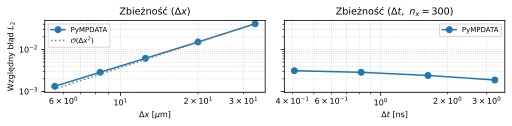

In [4]:
def rel_err(nx, nt):
    xg, _, _, h, _ = solve(nx, nt, outfreq=nt)
    ref = analytical(xg - mu_p * E * (t1 - t0), t1)
    return np.linalg.norm(h[-1] - ref) / np.linalg.norm(ref)

ncs = [60, 100, 160, 240, 360]
dxs = [0.2 / nc for nc in ncs]
nts_x = [int(np.ceil((2 * mu_p * E / d + 10 * D / d**2) * (t1 - t0))) for d in dxs]
err_x = [rel_err(nc, n) for nc, n in zip(ncs, nts_x)]
assert err_x[-1] < err_x[0] / 10

dxf = 0.2 / 300
nt0 = int(np.ceil((2 * mu_p * E / dxf + 10 * D / dxf**2) * (t1 - t0)))
nts_t = [nt0 * m for m in (1, 2, 4, 8)]
err_t = [rel_err(300, n) for n in nts_t]
dxs_um, dts_ns = np.array(dxs) * 1e4, (t1 - t0) / np.array(nts_t) * 1e9

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 1.9), sharey=True)
a1.loglog(dxs_um, err_x, 'o-', label='PyMPDATA')
a1.loglog(dxs_um, err_x[0] * (dxs_um / dxs_um[0])**2, ':', c='gray', label=r'$\mathcal{O}(\Delta x^2)$')
a1.set(xlabel=r'$\Delta x\ [\mu\mathrm{m}]$', ylabel=r'Względny błąd $L_2$', title=r'Zbieżność ($\Delta x$)')
a2.loglog(dts_ns, err_t, 'o-', label='PyMPDATA')
a2.set(xlabel=r'$\Delta t\ [\mathrm{ns}]$', title=r'Zbieżność ($\Delta t,\ n_x=300$)')
for a in (a1, a2):
    a.grid(True, which='both', ls=':', alpha=0.6)
    a.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 3. Wyniki i wnioski

* **Jak działają $\mathcal{E}$ i $\tau_p$:** bez pola ($\mathcal{E} = 0$) paczka zostaje w miejscu ($x = 0$), tylko się rozpływa i maleje. Po włączeniu pola $\mathcal{E} = 25\ \text{V/cm}$ jej środek przesuwa się dokładnie o $720\ \mu\text{m}$. Liczba nośników spada zgodnie ze wzorem $N' e^{-t/\tau_p}$ (test w kodzie potwierdza zgodność poniżej $1\%$), a stężenie nigdzie nie jest ujemne.
* **Dokładność obliczeń:** gdy jednocześnie zagęszczamy siatkę $\Delta x$ i zmniejszamy krok $\Delta t$, błąd spada kwadratowo — dwukrotnie gęstsza siatka daje około czterokrotnie mniejszy błąd (od ok. $4\%$ do $0{,}13\%$). Zmniejszanie samego kroku $\Delta t$ na jednej stałej siatce ($n_x = 300$) nie poprawia już wyniku, bo główny błąd wynika wtedy z rozmiaru komórek $\Delta x$, a większa liczba kroków lekko dokłada błędy z kolejnych iteracji.